# A4 · E2 — Does the churn model beat simple rules? (real data)

Calibrated mean(LR, LightGBM) ensemble. SMOTE-NC vs class weights is compared inside CV folds;
calibration (Platt) uses a held-out slice of the training split; the test split is untouched
until evaluation. Baselines: a visit-threshold rule and a single logistic regression.

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from anchorai.config import get_settings
from anchorai.features import build_features
from anchorai.scenario.tables import read_tables

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
SEED = get_settings().anchorai_seed
FIG, RES = Path("figures"), Path("results")
FIG.mkdir(exist_ok=True)
RES.mkdir(exist_ok=True)

tables = read_tables()
members = tables["members"]
labels = members.set_index("member_id")
features = build_features(members)
is_train = labels["split"] == "train"
print(len(members), "members;", is_train.sum(), "train /", (~is_train).sum(), "test")

4000 members; 3200 train / 800 test


In [2]:
from anchorai.discovery import churn

result = churn.train(features, labels["churn"], labels["split"], SEED)
card = result.card
metrics = ["f1", "precision", "recall", "pr_auc", "roc_auc", "brier"]
comparison = pd.DataFrame({
    "AnchorAI ensemble (calibrated)": card["test"],
    "single LR": card["baselines"]["single_lr"],
    card["baselines"]["visit_rule"]["rule"]: card["baselines"]["visit_rule"],
}).T[metrics].astype(float).round(3)
comparison.to_csv(RES / "e2_model_vs_baselines.csv")
comparison

,f1,precision,recall,pr_auc,roc_auc,brier
AnchorAI ensemble (calibrated),0.908,0.910,0.906,0.974,0.988,0.034
single LR,0.862,0.818,0.910,0.953,0.978,0.056
churn if visits per week this month <= 1.63,0.549,0.426,0.774,0.390,0.699,0.336


In [3]:
resampling = pd.DataFrame({r: card["resampling"][r] for r in churn.RESAMPLING}).T[["f1", "pr_auc", "brier"]].astype(float).round(4)
print("chosen:", card["resampling"]["chosen"])
resampling.to_csv(RES / "e2_resampling_cv.csv")
resampling

chosen: class_weight


,f1,pr_auc,brier
smote_nc,0.9064,0.9697,0.0386
class_weight,0.9074,0.9724,0.0392


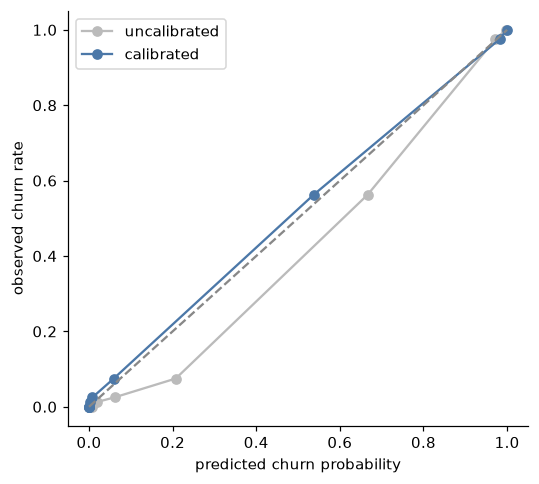

In [4]:
test = ~is_train
y, p = labels.loc[test, "churn"].to_numpy(), result.probabilities[test].to_numpy()
raw = result.model.raw_proba(features[test])

from sklearn.calibration import calibration_curve
fig, ax = plt.subplots(figsize=(5, 4.5))
for probs, name, colour in ((raw, "uncalibrated", "#bbbbbb"), (p, "calibrated", "#4c78a8")):
    obs, pred = calibration_curve(y, probs, n_bins=10, strategy="quantile")
    ax.plot(pred, obs, marker="o", label=name, color=colour)
ax.plot([0, 1], [0, 1], ls="--", color="#888")
ax.set_xlabel("predicted churn probability"); ax.set_ylabel("observed churn rate"); ax.legend()
fig.tight_layout(); fig.savefig(FIG / "e2_calibration.png"); plt.show()

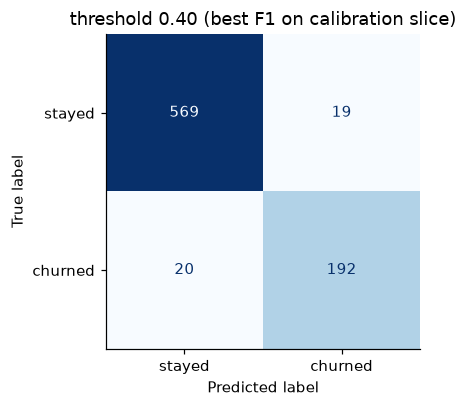

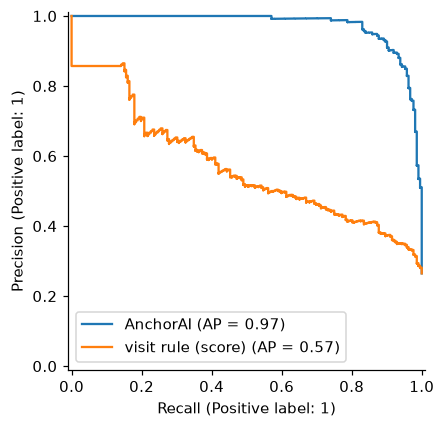

In [5]:
from sklearn.metrics import ConfusionMatrixDisplay, PrecisionRecallDisplay

fig, ax = plt.subplots(figsize=(4.2, 3.8))
ConfusionMatrixDisplay.from_predictions(y, p >= result.model.threshold, display_labels=["stayed", "churned"], ax=ax, colorbar=False, cmap="Blues")
ax.set_title(f"threshold {result.model.threshold:.2f} (best F1 on calibration slice)")
fig.tight_layout(); fig.savefig(FIG / "e2_confusion.png"); plt.show()

fig, ax = plt.subplots(figsize=(5, 4))
PrecisionRecallDisplay.from_predictions(y, p, ax=ax, name="AnchorAI")
rule = (-features.loc[test, "avg_class_frequency_current_month"]).to_numpy()
PrecisionRecallDisplay.from_predictions(y, rule, ax=ax, name="visit rule (score)")
fig.tight_layout(); fig.savefig(FIG / "e2_pr_curve.png"); plt.show()

## Drivers (SHAP)
Per-member drivers in the app are the mean of LR log-odds terms and LightGBM SHAP values.
The global view below is the LightGBM component's SHAP summary on the test split.

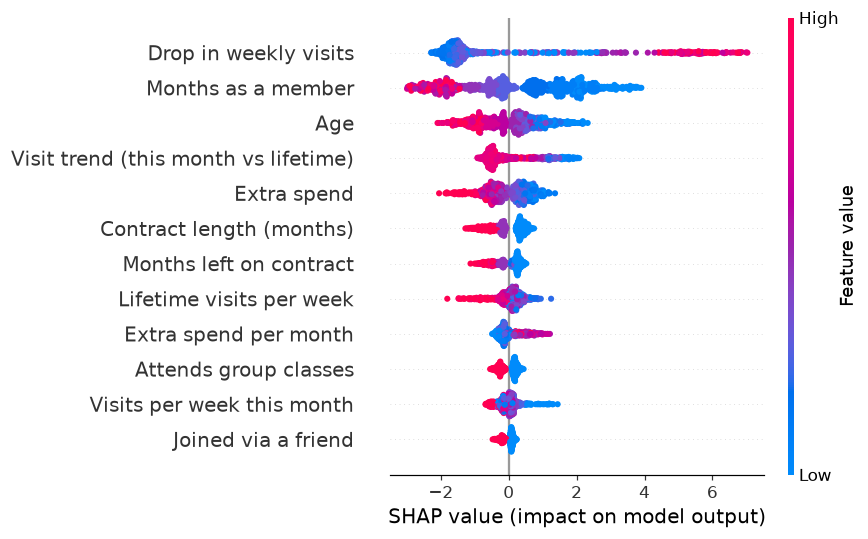

In [6]:
import shap
from anchorai.features import LABELS

booster = result.model.lgbm[-1]
x_test = features.loc[test, result.model.columns]
values = shap.TreeExplainer(booster).shap_values(x_test.to_numpy())
values = values[1] if isinstance(values, list) else values
shap.summary_plot(values, x_test.rename(columns=LABELS), show=False, max_display=12, plot_size=(8, 5))
plt.tight_layout(); plt.savefig(FIG / "e2_shap.png"); plt.show()

## Leakage and fairness

In [7]:
leak = pd.DataFrame({k: v["test"] for k, v in card["leakage"].items()}).T[metrics].astype(float).round(3)
leak.to_csv(RES / "e2_leakage_test.csv")
leak

,f1,precision,recall,pr_auc,roc_auc,brier
with_suspect,0.908,0.910,0.906,0.974,0.988,0.034
without_suspect,0.817,0.768,0.873,0.900,0.957,0.069


In [8]:
rows = []
for attribute, f in card["fairness"].items():
    for group, r in f["groups"].items():
        rows.append({"attribute": attribute, "group": group, **r})
fairness = pd.DataFrame(rows).round(3)
fairness.to_csv(RES / "e2_fairness.csv", index=False)
print({a: {"recall_gap": round(f["recall_gap"], 3), "fpr_gap": round(f["fpr_gap"], 3)} for a, f in card["fairness"].items()})
fairness

{'age_band': {'recall_gap': 0.507, 'fpr_gap': 0.139}, 'gender': {'recall_gap': 0.103, 'fpr_gap': 0.025}}


,attribute,group,n,churn_rate,recall,precision,fpr
0,age_band,18-25,108,0.611,0.985,0.915,0.143
1,age_band,26-30,425,0.289,0.943,0.906,0.040
2,age_band,31+,267,0.086,0.478,0.917,0.004
3,gender,0,389,0.260,0.851,0.869,0.045
4,gender,1,411,0.270,0.955,0.946,0.020


In [9]:
older = fairness[(fairness.attribute == "age_band") & (fairness.group == "31+")].iloc[0]
print(f"31+ members: {older.n} in test, churn rate {older.churn_rate:.1%}, recall {older.recall:.2f}")
print("Mitigation for staff use: a lower review threshold for this band, or treat their medium-risk members as at-risk.")

31+ members: 267 in test, churn rate 8.6%, recall 0.48
Mitigation for staff use: a lower review threshold for this band, or treat their medium-risk members as at-risk.


**Reading.** The calibrated ensemble beats both baselines on F1 and PR-AUC, and calibration
brings predicted probabilities onto the observed rates, which the optimiser relies on. The
largest fairness gap is recall by age: churn among members aged 31+ is rare (about 9%) and the
model misses about half of it. This is reported, not hidden; see the mitigation above.